In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore


## Simulated Hysteresis [Force(Derecruitment)/Force(Recruitment)-1] Vs. Force(Recruitment)

In [3]:
#Importing the spike array file of the Julia Model
with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/DR_I05_hsigmoid_26A.jld2", "r") as file:
    spike_array = file["spike_array"][:].T

In [357]:
#Finding first and last spike of each neuron
first_spike = np.zeros(spike_array.shape[0], dtype=int)
last_spike = np.zeros(spike_array.shape[0], dtype=int)

for i in range(spike_array.shape[0]):

    first_spike[i] = next((j for j, x in enumerate(spike_array[i, :]) if x == 1), None)

    for k in range(spike_array[i, :].shape[0] - 1, -1, -1):
        if spike_array[i, k] == 1:
            last_spike[i] = k
            break

print("First spikes:", first_spike)
print("Last spikes:", last_spike)

First spikes: [158046 160614 167791 175567 182101 183049 246307 234825 294190 253000]
Last spikes: [462424 460550 452438 439837 433045 431081 353718 358092 320968 336921]


In [358]:
#Excitatory Input 
amplitude = 0.4
sim_length = 560000
half_triang = sim_length // 2 
flat_line = np.full(20000, -0.1)
up = np.linspace(-0.1, amplitude, num=half_triang + 1)
down = np.linspace(amplitude, -0.1, num=sim_length - half_triang + 1)
exc = np.concatenate([flat_line, up[1:], down[1:], flat_line])

In [359]:
force_first = np.zeros(spike_array.shape[0])
force_last = np.zeros(spike_array.shape[0])

for i in range(spike_array.shape[0]):
    force_first[i]= exc[first_spike[i]]
    force_last[i]= exc[last_spike[i]]

print("First spikes:", force_first)
print("Last spikes:", force_last)

First spikes: [0.1465125  0.15109821 0.16391429 0.1778     0.18946786 0.19116071
 0.30412143 0.28361786 0.38962679 0.31607321]
Last spikes: [0.10995536 0.11330179 0.1277875  0.15028929 0.16241786 0.165925
 0.30407321 0.2962625  0.36255536 0.33406786]


In [360]:
def normalize_to_range(vector, new_min, new_max):
    min_val = np.min(vector)
    max_val = np.max(vector)
    return ((vector - min_val) / (max_val - min_val)) * (new_max - new_min) + new_min



# Getting recruitment and derecruitment in terms of the %MVC
simulated_values = np.concatenate((force_first,force_last))
normalized_recr = normalize_to_range(simulated_values, 0, 100)
print("Normalized Recr: ", normalized_recr)
recr_sim = normalized_recr[:10]
derecr_sim = normalized_recr[10:20]



Normalized Recr:  [ 13.07146141  14.71114062  19.29368647  24.25869643  28.43068397
  29.03598611  69.42649538  62.09518823 100.          73.70000511
   0.           1.19655718   6.37610461  14.42189815  18.75861981
  20.01264239  69.40925576  66.61643766  90.32027379  80.13421362]


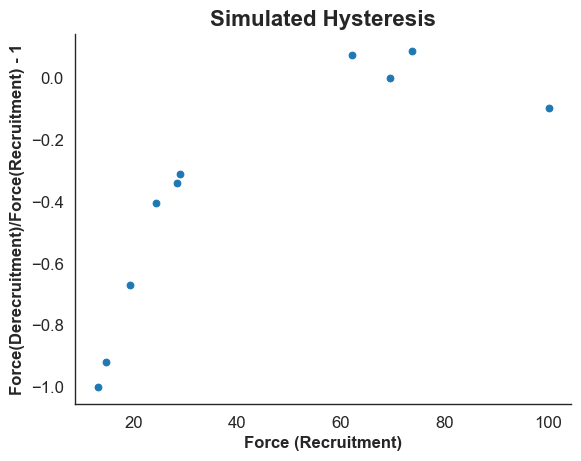

In [361]:
sns.set_style("white")

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12


norm_hysteresis=derecr_sim/recr_sim-1
plt.scatter(recr_sim,norm_hysteresis)

plt.title('Simulated Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
sns.despine()


## Experimental distribution

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_52579/3627334739.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned = all_dfs.groupby(pd.cut(all_dfs.iloc[:, 0], bins=bin_edges))


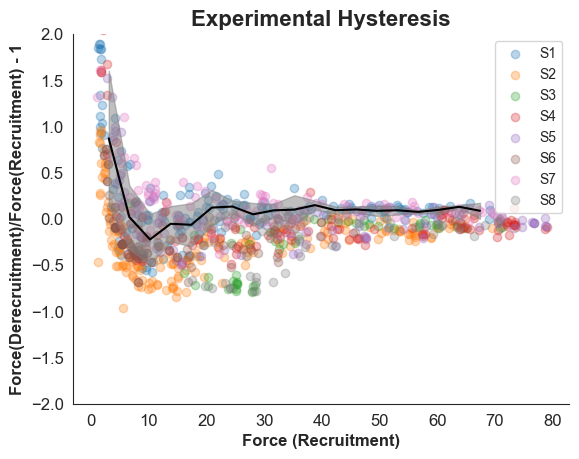

In [111]:

sns.set_style("white")

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

def process_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna(how='all')
    df['hysteresis'] = df.iloc[:, 1] / df.iloc[:, 0] - 1
    df['zscore'] = zscore(df['hysteresis'])
    return df[df['zscore'].abs() <= 3] 

df1 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S1.csv')
df2 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S2.csv')
df3 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S3.csv')
df4 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S4.csv')
df5 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S5_.csv')
df6 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S6.csv')
df7 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S7.csv')
df8 = process_data('/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/csv_subjects/S8.csv')

all_dfs = pd.concat([df1, df2, df3, df4,df5,df6,df7,df8])

#  bin edges for the x-axis
bin_edges = np.linspace(all_dfs.iloc[:, 0].min(), all_dfs.iloc[:, 0].max(), num=20) 
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

binned = all_dfs.groupby(pd.cut(all_dfs.iloc[:, 0], bins=bin_edges))
means = binned['hysteresis'].mean()
std_devs = binned['hysteresis'].std()


plt.scatter(df1.iloc[:, 0], df1['hysteresis'], alpha=0.3, label='S1')
plt.scatter(df2.iloc[:, 0], df2['hysteresis'], alpha=0.3, label='S2')
plt.scatter(df3.iloc[:, 0], df3['hysteresis'], alpha=0.3, label='S3')
plt.scatter(df4.iloc[:, 0], df4['hysteresis'], alpha=0.3, label='S4')
plt.scatter(df5.iloc[:, 0], df5['hysteresis'], alpha=0.3, label='S5')
plt.scatter(df6.iloc[:, 0], df6['hysteresis'], alpha=0.3, label='S6')
plt.scatter(df7.iloc[:, 0], df7['hysteresis'], alpha=0.3, label='S7')
plt.scatter(df8.iloc[:, 0], df8['hysteresis'], alpha=0.3, label='S8')


plt.plot(bin_centers, means, '-', color='black')#label='Evolving Mean')
plt.fill_between(bin_centers, means - std_devs, means + std_devs, color='gray', alpha=0.5)#, label='Variance')

#######
plt.ylim(-2, 2)


plt.title('Experimental Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Force (Recruitment)', fontsize=12, fontweight='bold')
plt.ylabel('Force(Derecruitment)/Force(Recruitment) - 1', fontsize=12, fontweight='bold')
plt.legend()

sns.despine()

plt.show()


In [109]:
all_values_hysteresis=np.concatenate((df1["hysteresis"],df2["hysteresis"],df3["hysteresis"],df4["hysteresis"],df5["hysteresis"],df6["hysteresis"],df7["hysteresis"],df8["hysteresis"]))
# all_values_hysteresis= sorted(all_values_hysteresis)
d=20
binned_hyst = np.zeros((1, len(all_values_hysteresis) // d))


count = 0  
for i in range(1, len(all_values_hysteresis)):
    if i % d == 0:
        mean_value = np.mean(all_values_hysteresis[i-d:i])
        binned_hyst[0, count] = mean_value
        count += 1  

# print(binned_hyst)

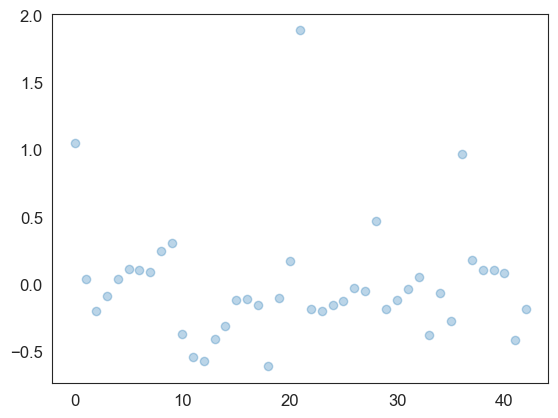

In [110]:
sns.set_style("white")

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.scatter(np.arange(len(binned_hyst[0,:])),binned_hyst,alpha=0.3)

In [98]:
len(binned_hyst[0,:])
np.size(binned_hyst)

175

In [71]:
np.size(all_values_hysteresis)/10

87.8

In [52]:
all_values_hysteresis= sorted(all_values_hysteresis)


In [51]:
all_values_hysteresis=np.concatenate((df1["hysteresis"],df2["hysteresis"],df3["hysteresis"],df4["hysteresis"],df5["hysteresis"],df6["hysteresis"],df7["hysteresis"],df8["hysteresis"]))
print(sorted(all_values_hysteresis))


[-0.970534279445541, -0.847311784085925, -0.7959165513210351, -0.7944571913592616, -0.7843570586802746, -0.7814548833946053, -0.7810602114355625, -0.7804976998442057, -0.779650339199151, -0.775816191399716, -0.7619808225137846, -0.7580371694470667, -0.7556857475903588, -0.7541472335939929, -0.7514613719426212, -0.7505747378565621, -0.747446879361773, -0.7458890328586465, -0.7436091792683095, -0.7436091792683095, -0.7407044431016466, -0.7310066546248684, -0.7296094077218647, -0.7290497674076262, -0.7276390257812162, -0.7220840511231494, -0.7206782487214003, -0.715584995460262, -0.7143647623906961, -0.7010827634119179, -0.7000907742904396, -0.7000907742904396, -0.6980782370514935, -0.6975810365279778, -0.6967965623539434, -0.6955573531119519, -0.6871884180007081, -0.6856195622556381, -0.6853229895850306, -0.6808022013042654, -0.6808009612725701, -0.6804989488888453, -0.6760441588931603, -0.6726979255780305, -0.6686484865285762, -0.660442187033164, -0.6597456316684707, -0.6576240797991748

In [289]:
#Importing the spike array file of the Julia Model
with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap1.jld2", "r") as file:
    heatmap1 = file["hysteresis_for_each_inh"][:]

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap2.jld2", "r") as file:
    heatmap2 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap3.jld2", "r") as file:
    heatmap3 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap4.jld2", "r") as file:
    heatmap4 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap5.jld2", "r") as file:
    heatmap5 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap6.jld2", "r") as file:
    heatmap6 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap7.jld2", "r") as file:
    heatmap7 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap8.jld2", "r") as file:
    heatmap8 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap9.jld2", "r") as file:
    heatmap9 = file["hysteresis_for_each_inh"][:].T

with h5py.File("/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Heatmap_values/hysteresis_heatmap10.jld2", "r") as file:
    heatmap10 = file["hysteresis_for_each_inh"][:].T

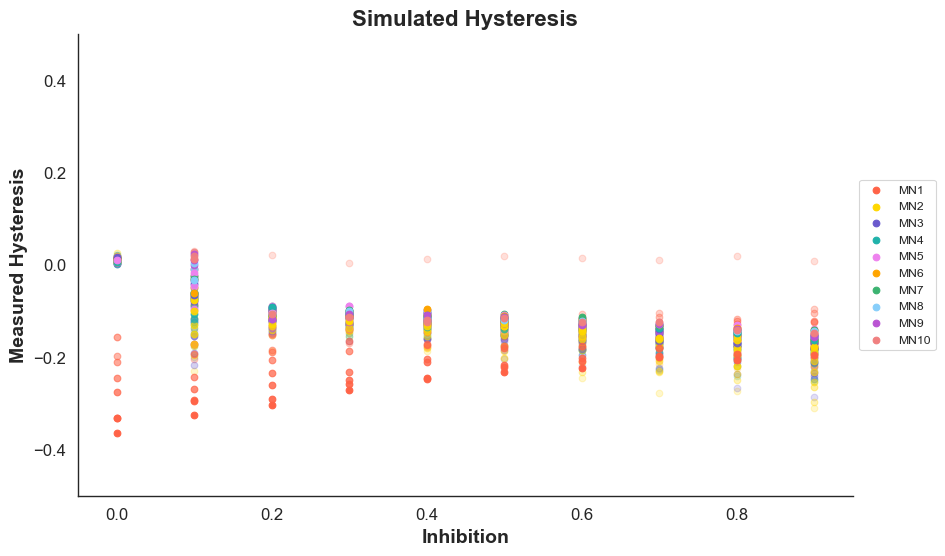

In [324]:
sns.set_style("white")
plt.figure(figsize=(10, 6))
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

colors = [
    "#FF6347",  # Tomato
    "#FFD700",  # Gold
    "#6A5ACD",  # Slate Blue
    "#20B2AA",  # Light Sea Green
    "#EE82EE",  # Violet
    "#FFA500",  # Orange
    "#3CB371",  # Medium Sea Green
    "#87CEFA",  # Light Sky Blue
    "#BA55D3",  # Medium Orchid
    "#F08080"   # Light Coral
]

flat_data = heatmap1.flatten()
flat_data2 = heatmap2.flatten()
flat_data3 = heatmap3.flatten()
flat_data4 = heatmap4.flatten()
flat_data5 = heatmap5.flatten()
flat_data6 = heatmap6.flatten()
flat_data7 = heatmap7.flatten()
flat_data8 = heatmap8.flatten()
flat_data9 = heatmap9.flatten()
flat_data10 = heatmap10.flatten()


values = np.round([0.1 * i for i in range(len(colors))],1)

for i in range(10):
    alphas = np.linspace(0.2, 1, num=10) #first values are without neuromod and they are kind of transparent
    for j in range(10):
        if i==9 and j==9:
            plt.scatter(values[i], flat_data[i*10 + j], alpha=alphas[j], color=colors[0],label='MN1')
            plt.scatter(values[i], flat_data2[i*10 + j], alpha=alphas[j], color=colors[1],label='MN2')
            plt.scatter(values[i], flat_data3[i*10 + j], alpha=alphas[j], color=colors[2],label='MN3')
            plt.scatter(values[i], flat_data4[i*10 + j], alpha=alphas[j], color=colors[3],label='MN4')
            plt.scatter(values[i], flat_data5[i*10 + j], alpha=alphas[j], color=colors[4],label='MN5')
            plt.scatter(values[i], flat_data6[i*10 + j], alpha=alphas[j], color=colors[5],label='MN6')
            plt.scatter(values[i], flat_data7[i*10 + j], alpha=alphas[j], color=colors[6],label='MN7')
            plt.scatter(values[i], flat_data8[i*10 + j], alpha=alphas[j], color=colors[7],label='MN8')
            plt.scatter(values[i], flat_data9[i*10 + j], alpha=alphas[j], color=colors[8],label='MN9')
            plt.scatter(values[i], flat_data10[i*10 + j], alpha=alphas[j], color=colors[9],label='MN10')
        else: 
            plt.scatter(values[i], flat_data[i*10 + j], alpha=alphas[j], color=colors[0])
            plt.scatter(values[i], flat_data2[i*10 + j], alpha=alphas[j], color=colors[1])
            plt.scatter(values[i], flat_data3[i*10 + j], alpha=alphas[j], color=colors[2])
            plt.scatter(values[i], flat_data4[i*10 + j], alpha=alphas[j], color=colors[3])
            plt.scatter(values[i], flat_data5[i*10 + j], alpha=alphas[j], color=colors[4])
            plt.scatter(values[i], flat_data6[i*10 + j], alpha=alphas[j], color=colors[5])
            plt.scatter(values[i], flat_data7[i*10 + j], alpha=alphas[j], color=colors[6])
            plt.scatter(values[i], flat_data8[i*10 + j], alpha=alphas[j], color=colors[7])
            plt.scatter(values[i], flat_data9[i*10 + j], alpha=alphas[j], color=colors[8])
            plt.scatter(values[i], flat_data10[i*10 + j], alpha=alphas[j], color=colors[9])
    

        

plt.title('Simulated Hysteresis', fontsize=16, fontweight='bold')
plt.xlabel('Inhibition')
plt.ylabel('Measured Hysteresis')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
plt.ylim(-0.5, 0.5)
plt.xlim(-0.05, 0.95)
plt.show()


In [309]:
values

array([0., 0., 0., 0., 0., 0., 1., 1., 1., 1.])

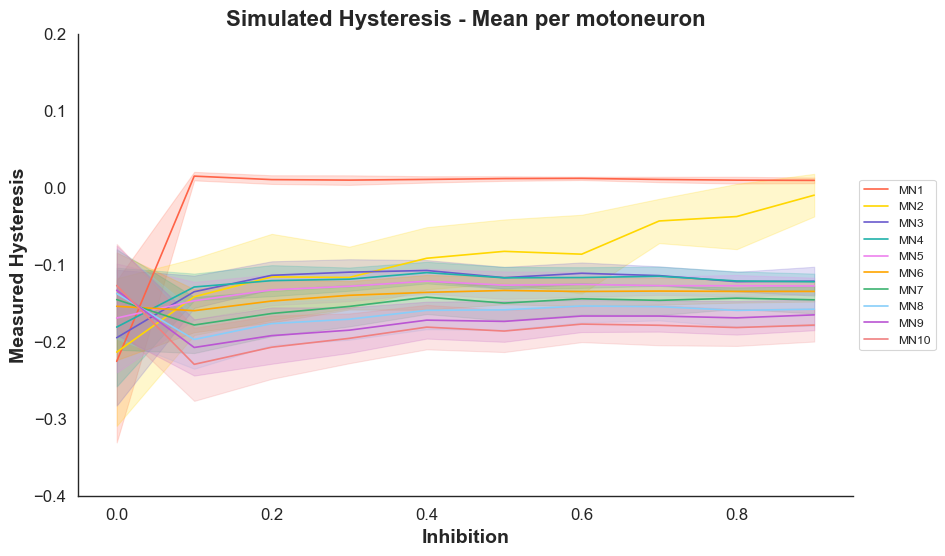

In [328]:
sns.set_style("white")
plt.figure(figsize=(10, 6))
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

colors = [
    "#FF6347",  # Tomato
    "#FFD700",  # Gold
    "#6A5ACD",  # Slate Blue
    "#20B2AA",  # Light Sea Green
    "#EE82EE",  # Violet
    "#FFA500",  # Orange
    "#3CB371",  # Medium Sea Green
    "#87CEFA",  # Light Sky Blue
    "#BA55D3",  # Medium Orchid
    "#F08080"   # Light Coral
]

flat_data = heatmap1.flatten()
flat_data2 = heatmap2.flatten()
flat_data3 = heatmap3.flatten()
flat_data4 = heatmap4.flatten()
flat_data5 = heatmap5.flatten()
flat_data6 = heatmap6.flatten()
flat_data7 = heatmap7.flatten()
flat_data8 = heatmap8.flatten()
flat_data9 = heatmap9.flatten()
flat_data10 = heatmap10.flatten()

datasets = [flat_data, flat_data2, flat_data3, flat_data4, flat_data5, flat_data6, flat_data7, flat_data8, flat_data9, flat_data10]

values = [0.1 * i for i in range(10)]

for i, color in enumerate(colors):
    data_points = np.array([[np.nan if x > 99 else x for x in dataset[i*10:(i+1)*10]] for dataset in datasets])
    means = np.nanmean(data_points, axis=1)
    std_devs = np.nanstd(data_points, axis=1)
    # std_devs=0
    plt.plot(values, means, label=f'MN{i+1}', color=color)
    plt.fill_between(values, means - std_devs, means + std_devs, color=color, alpha=0.2)

# Set plot titles and labels
plt.title('Simulated Hysteresis - Mean per motoneuron', fontsize=16, fontweight='bold')
plt.xlabel('Inhibition')
plt.ylabel('Measured Hysteresis')

# Configure legend and axes limits
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
sns.despine()
plt.ylim(-0.4, 0.2)
plt.xlim(-0.05, 0.95)

# Display the plot
plt.show()


In [322]:
i=0
data_points = np.array([dataset[i*10:(i+1)*10] for dataset in datasets])
means = np.mean(data_points, axis=0)
data_points.max()

100.0